# Caro AlphaZero V2 (SE-ResNet Thuần Tích Chập + MCTS Vectorized)

Sổ tay cờ Caro (Gomoku) áp dụng Deep Reinforcement Learning nâng cấp toàn diện:
- **Đầu vào 4 kênh (Feature Engineering):** [Quân ta, Quân địch, Nước đi gần nhất (Last Move), Lợi thế lượt đi (Turn Plane)].
- **Mạng SE-ResNet Thuần Tích Chập (Fully-Convolutional):** Loại bỏ lớp Linear cố định, giữ nguyên tính đối xứng không gian 2D, thích ứng linh hoạt mọi kích thước bàn cờ.
- **Soft Tactical Prior:** Tích hợp điểm thưởng chiến thuật (thắng ngay, chặn 5, tạo 4 mở, chặn 3 mở) trực tiếp vào logits tiên nghiệm của MCTS, giúp mạng nơ-ron tự học chiến thuật tự nhiên qua Cross-Entropy Loss.
- **MCTS Vectorized:** Tối ưu hóa bước duyệt cây PUCT bằng NumPy vectorization, tăng tốc độ tính toán gấp nhiều lần.
- **Bể đối thủ lịch sử (Opponent Pool):** 80% ván tự đấu, 20% ván đấu lại các phiên bản mô hình cũ, ngăn ngừa hiện tượng quên bài (Policy Cycling).
- **Luật cờ Caro Việt Nam:** Chuẩn 5 quân (chống Overline) và luật chặn 2 đầu chặt chẽ.

*Hướng dẫn:* Mặc định `MODE = 'smoke_test'` để chạy thử toàn bộ notebook trong vài giây; đổi sang `MODE = 'training'` khi bắt đầu huấn luyện thật.


## 0. Khởi tạo môi trường, Thư viện & Thư mục Checkpoint

- Kiểm tra phần cứng GPU qua `nvidia-smi`.
- Tự động khởi tạo thư mục lưu trữ checkpoint cục bộ (`checkpoints/`).
- Bật chế độ tăng tốc tính toán hỗn hợp **Automatic Mixed Precision (AMP FP16)** trên GPU CUDA.


In [1]:
#!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu134


In [2]:
#!python -c "import torch; print('PyTorch Version:', torch.__version__, '| CUDA:', torch.cuda.is_available(), '| GPU:', torch.cuda.get_device_name(0))"


In [3]:
# Kiểm tra trạng thái GPU hệ thống
!nvidia-smi


Wed Nov  4 11:48:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 617.14                 KMD Version: 617.14        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   47C    P8              2W /   80W |     755MiB /   6141MiB |     14%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import os
import json
import math
import random
from collections import deque
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

# Thiết lập hạt giống ngẫu nhiên để tái lập kết quả
SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Tự động chọn thiết bị tính toán: ưu tiên CUDA (GPU RTX 4050), fallback về CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

# Thiết lập thư mục lưu trữ checkpoint cục bộ
PROJECT_DIR = Path(os.getcwd()).resolve()
SAVE_DIR = PROJECT_DIR / "checkpoints"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Thư mục dự án: {PROJECT_DIR}")
print(f"Thư mục lưu Checkpoint cục bộ: {SAVE_DIR}")
print(f"Thiết bị sử dụng: {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    print(f"Chế độ AMP (FP16): {'Bật' if USE_AMP else 'Tắt'}")
else:
    print("Đang chạy trên CPU (khuyến nghị cài PyTorch CUDA để khai thác GPU RTX 4050).")


Thư mục dự án: .
Thư mục lưu Checkpoint cục bộ: .\checkpoints
Thiết bị sử dụng: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.00 GB
Chế độ AMP (FP16): Bật


.\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Cấu hình & Siêu tham số (Hyperparameters & Config)

Thiết lập cấu hình tập trung trong `Config` với 2 chế độ định sẵn:
- `MODE = 'smoke_test'`: Tham số thu gọn (bàn 10x10, 8 sims) để kiểm tra code chạy thông suốt trong vài giây.
- `MODE = 'training'`: Tham số chuẩn cho bàn cờ Caro 15x15 quốc tế (150 MCTS sims, 4 SE-ResBlocks, 64 channels, Opponent Pool 20%).


In [5]:
# Chọn chế độ: 'smoke_test' (kiểm tra nhanh) hoặc 'training' (huấn luyện thật)
MODE = "training"

@dataclass
class Config:
    """Cấu hình toàn bộ tham số cho môi trường, mô hình và huấn luyện."""

    # Tham số bàn cờ
    board_size: int = 15       # Chuẩn thi đấu cờ Caro 15x15 (225 ô)
    win_length: int = 5        # Số quân liên tiếp để chiến thắng theo luật Việt Nam

    # Tham số MCTS & Heuristic
    simulations: int = 100     # 100 simulations/nước: cân bằng tối ưu giữa chiều sâu và tốc độ
    c_puct: float = 1.5        # Hệ số cân bằng khám phá/khai thác PUCT
    dirichlet_alpha: float = 0.05   # Nhiễu Dirichlet tối ưu cho bàn 15x15 (225 ô)
    dirichlet_epsilon: float = 0.25 # Tỉ lệ pha trộn nhiễu Dirichlet
    temperature_moves: int = 10     # Số nước đầu dùng nhiệt độ tau=1.0 để khám phá

    # Tham số mạng SE-ResNet Thuần Tích Chập
    channels: int = 64         # Số kênh tích chập
    residual_blocks: int = 4   # Số khối SE-ResNet

    # Tham số huấn luyện & Opponent Pool
    learning_rate: float = 1e-3     # Tốc độ học của AdamW
    weight_decay: float = 1e-4      # Hệ số suy giảm trọng số L2
    batch_size: int = 64            # Kích thước batch huấn luyện
    buffer_capacity: int = 30000    # Sức chứa Replay Buffer
    self_play_games: int = 5        # Số ván tự đấu sinh dữ liệu mỗi vòng
    train_steps: int = 25           # Số bước cập nhật gradient mỗi vòng
    num_iterations: int = 50        # Tổng số vòng lặp huấn luyện
    save_interval: int = 5          # Chu kỳ lưu checkpoint định kỳ
    pool_size: int = 8              # Số model lịch sử lưu trong Opponent Pool
    pool_play_ratio: float = 0.20   # Tỉ lệ đấu với đối thủ lịch sử (20% ván)


# Áp dụng cấu hình theo chế độ đã chọn
if MODE == "training":
    config = Config(
        board_size=15,
        win_length=5,
        simulations=100,         # 100 simulations kết hợp vectorization & root heuristic chạy cực nhanh
        dirichlet_alpha=0.05,
        temperature_moves=10,
        channels=64,
        residual_blocks=4,
        learning_rate=1e-3,
        weight_decay=1e-4,
        batch_size=64,
        buffer_capacity=30000,
        self_play_games=5,
        train_steps=25,
        num_iterations=50,
        save_interval=5,
        pool_size=8,
        pool_play_ratio=0.20
    )
else:
    # Cấu hình kiểm tra nhanh (Smoke Test)
    config = Config(
        board_size=10,
        win_length=5,
        simulations=8,
        dirichlet_alpha=0.3,
        temperature_moves=4,
        channels=32,
        residual_blocks=2,
        learning_rate=1e-3,
        weight_decay=1e-4,
        batch_size=8,
        buffer_capacity=2000,
        self_play_games=1,
        train_steps=2,
        num_iterations=2,
        save_interval=1,
        pool_size=4,
        pool_play_ratio=0.0
    )

print(f"Chế độ hiện tại: [{MODE.upper()}]")
print(f"Cấu hình: Bàn cờ {config.board_size}x{config.board_size}, ăn {config.win_length} quân thắng (Luật Việt Nam).")
print(f"MCTS Simulations: {config.simulations} | Dirichlet Alpha: {config.dirichlet_alpha}")
print(f"SE-ResNet: {config.residual_blocks} blocks x {config.channels} channels (Thuần tích chập)")
print(f"Dự kiến chạy: {config.num_iterations} vòng lặp, mỗi vòng {config.self_play_games} ván tự đấu.")


Chế độ hiện tại: [TRAINING]
Cấu hình: Bàn cờ 15x15, ăn 5 quân thắng (Luật Việt Nam).
MCTS Simulations: 100 | Dirichlet Alpha: 0.05
SE-ResNet: 4 blocks x 64 channels (Thuần tích chập)
Dự kiến chạy: 50 vòng lặp, mỗi vòng 5 ván tự đấu.


## 2. Môi trường & Luật cờ Caro (Game Environment)

- **Biểu diễn 4 kênh (Feature Engineering):**
  - Kênh 0: Vị trí quân của người chơi hiện tại.
  - Kênh 1: Vị trí quân của đối thủ.
  - Kênh 2: Nước đi gần nhất (1 tại `last_move`, 0 ở các ô khác) — giúp mạng chú ý ngay vào điểm nóng vừa xuất hiện.
  - Kênh 3: Lợi thế lượt đi (toàn 1 nếu là Đen/Player 1 đi trước, toàn 0 nếu là Trắng/Player -1 đi sau).
- **Hàm `check_win`:** Chuẩn luật Caro Việt Nam (đúng 5 quân, không tính thắng nếu bị chặn cả 2 đầu hoặc quá 5 quân).
- **Hàm `get_tactical_bonuses` (Soft Prior):** Tính điểm thưởng chiến thuật 4 cấp độ (thắng ngay, chặn 5, tạo 4 mở, chặn 3 mở) cộng vào logits của MCTS.


In [6]:
class GomokuEnv:
    """Môi trường bàn cờ Caro (Gomoku) theo luật Việt Nam và biểu diễn 4 kênh."""

    def __init__(self, config: Config):
        self.size = config.board_size
        self.win_length = config.win_length
        self.reset()

    def reset(self):
        """Khởi tạo lại ván cờ về trạng thái rỗng."""
        self.board = np.zeros((self.size, self.size), dtype=np.int8)
        self.current_player = 1  # 1: Đen (đi trước), -1: Trắng (đi sau)
        self.last_move = None
        self.done = False
        self.winner = 0  # 1: Đen thắng, -1: Trắng thắng, 0: Hòa/Chưa xong
        return self.state()

    def state(self) -> np.ndarray:
        """Trả về tensor trạng thái 4 kênh:
        Kênh 0: Vị trí quân của người chơi hiện tại.
        Kênh 1: Vị trí quân của đối thủ.
        Kênh 2: Nước đi gần nhất (1 tại last_move, 0 ở các ô khác).
        Kênh 3: Lợi thế lượt đi (toàn 1 nếu là Đen/Player 1, toàn 0 nếu là Trắng/Player -1).
        """
        s = np.zeros((4, self.size, self.size), dtype=np.float32)
        s[0] = (self.board == self.current_player).astype(np.float32)
        s[1] = (self.board == -self.current_player).astype(np.float32)
        if self.last_move is not None:
            s[2, self.last_move[0], self.last_move[1]] = 1.0
        if self.current_player == 1:
            s[3].fill(1.0)
        return s

    def check_win(self, x: int, y: int, board: np.ndarray = None) -> bool:
        """Kiểm tra thắng theo Luật Caro Việt Nam.
        Chuỗi đúng win_length quân (5 quân) và không bị đối thủ chặn cả 2 đầu.
        Nếu >= 6 quân không tính thắng.
        """
        b = self.board if board is None else board
        player = b[x, y]
        if player == 0:
            return False

        opponent = -player

        for dx, dy in ((0, 1), (1, 0), (1, 1), (1, -1)):
            count = 1

            # Quét chiều dương
            nx, ny = x + dx, y + dy
            while 0 <= nx < self.size and 0 <= ny < self.size and b[nx, ny] == player:
                count += 1
                nx += dx
                ny += dy
            head_blocked = (
                not (0 <= nx < self.size and 0 <= ny < self.size)
                or b[nx, ny] == opponent
            )

            # Quét chiều âm
            px, py = x - dx, y - dy
            while 0 <= px < self.size and 0 <= py < self.size and b[px, py] == player:
                count += 1
                px -= dx
                py -= dy
            tail_blocked = (
                not (0 <= px < self.size and 0 <= py < self.size)
                or b[px, py] == opponent
            )

            if count == self.win_length and not (head_blocked and tail_blocked):
                return True

        return False

    def is_open_four(self, x: int, y: int, player: int, board: np.ndarray = None) -> bool:
        """Kiểm tra xem đặt quân player tại (x, y) có tạo thành 4 quân mở 2 đầu (Live 4) không."""
        b = self.board if board is None else board
        for dx, dy in ((0, 1), (1, 0), (1, 1), (1, -1)):
            count = 1
            # Quét chiều dương
            nx, ny = x + dx, y + dy
            while 0 <= nx < self.size and 0 <= ny < self.size and b[nx, ny] == player:
                count += 1
                nx += dx
                ny += dy
            head_open = (0 <= nx < self.size and 0 <= ny < self.size) and (b[nx, ny] == 0)

            # Quét chiều âm
            px, py = x - dx, y - dy
            while 0 <= px < self.size and 0 <= py < self.size and b[px, py] == player:
                count += 1
                px -= dx
                py -= dy
            tail_open = (0 <= px < self.size and 0 <= py < self.size) and (b[px, py] == 0)

            if count == self.win_length - 1 and head_open and tail_open:
                return True
        return False

    def is_any_four(self, x: int, y: int, player: int, board: np.ndarray = None) -> bool:
        """Kiểm tra đặt quân player tại (x, y) có tạo thành 4 quân có ít nhất 1 đầu mở không.
        (Bao gồm cả nối dài chuỗi 3 hoặc lấp lỗ hổng trong chuỗi đứt X X . X).
        """
        b = self.board if board is None else board
        opponent = -player
        for dx, dy in ((0, 1), (1, 0), (1, 1), (1, -1)):
            count = 1
            nx, ny = x + dx, y + dy
            while 0 <= nx < self.size and 0 <= ny < self.size and b[nx, ny] == player:
                count += 1
                nx += dx
                ny += dy
            head_blocked = (
                not (0 <= nx < self.size and 0 <= ny < self.size)
                or b[nx, ny] == opponent
            )

            px, py = x - dx, y - dy
            while 0 <= px < self.size and 0 <= py < self.size and b[px, py] == player:
                count += 1
                px -= dx
                py -= dy
            tail_blocked = (
                not (0 <= px < self.size and 0 <= py < self.size)
                or b[px, py] == opponent
            )

            if count == self.win_length - 1 and not (head_blocked and tail_blocked):
                return True
        return False

    def is_open_three(self, x: int, y: int, player: int, board: np.ndarray = None) -> bool:
        """Kiểm tra đặt quân player tại (x, y) có tạo thành 3 quân mở 2 đầu (Live 3) không.
        (Mở rộng từ đường 2 quân lên đường 3 quân mở).
        """
        b = self.board if board is None else board
        for dx, dy in ((0, 1), (1, 0), (1, 1), (1, -1)):
            count = 1
            nx, ny = x + dx, y + dy
            while 0 <= nx < self.size and 0 <= ny < self.size and b[nx, ny] == player:
                count += 1
                nx += dx
                ny += dy
            head_open = (0 <= nx < self.size and 0 <= ny < self.size) and (b[nx, ny] == 0)

            px, py = x - dx, y - dy
            while 0 <= px < self.size and 0 <= py < self.size and b[px, py] == player:
                count += 1
                px -= dx
                py -= dy
            tail_open = (0 <= px < self.size and 0 <= py < self.size) and (b[px, py] == 0)

            if count == self.win_length - 2 and head_open and tail_open:
                return True
        return False

    def legal_actions(self) -> np.ndarray:
        """Danh sách chỉ số các ô trống hợp lệ."""
        return np.flatnonzero(self.board.ravel() == 0)

    def get_tactical_bonuses(self, player: int, board: np.ndarray = None) -> np.ndarray:
        """Tính điểm thưởng chiến thuật (Soft Prior) cho tất cả các ô hợp lệ.
        - Thắng ngay (5 quân): +15.0
        - Chặn đối thủ thắng ngay: +12.0
        - Tạo 4 mở 2 đầu (Live 4): +10.0
        - Chặn đối thủ tạo 4 mở (chặn Live 3): +8.0
        - Tạo 4 quân có 1+ đầu mở (lấp lỗ hổng hoặc nối dài): +5.0
        - Chặn đối thủ tạo 4 quân (chặn chuỗi đứt X X . X): +4.5
        - Tạo 3 mở 2 đầu (từ đường 2 mở): +3.5
        - Chặn đối thủ tạo 3 mở 2 đầu: +3.0
        """
        b = self.board if board is None else board
        bonuses = np.zeros(self.size * self.size, dtype=np.float32)
        empty = np.flatnonzero(b.ravel() == 0)
        opponent = -player

        for action in empty:
            x, y = divmod(int(action), self.size)

            # 1. Đánh giá tấn công (Phía ta)
            b[x, y] = player
            if self.check_win(x, y, board=b):
                bonuses[action] = max(bonuses[action], 15.0)
            elif self.is_open_four(x, y, player, board=b):
                bonuses[action] = max(bonuses[action], 10.0)
            elif self.is_any_four(x, y, player, board=b):
                bonuses[action] = max(bonuses[action], 5.0)
            elif self.is_open_three(x, y, player, board=b):
                bonuses[action] = max(bonuses[action], 3.5)
            b[x, y] = 0

            # 2. Đánh giá phòng thủ (Phía đối thủ)
            b[x, y] = opponent
            if self.check_win(x, y, board=b):
                bonuses[action] = max(bonuses[action], 12.0)
            elif self.is_open_four(x, y, opponent, board=b):
                bonuses[action] = max(bonuses[action], 8.0)
            elif self.is_any_four(x, y, opponent, board=b):
                bonuses[action] = max(bonuses[action], 4.5)
            elif self.is_open_three(x, y, opponent, board=b):
                bonuses[action] = max(bonuses[action], 3.0)
            b[x, y] = 0

        return bonuses

    def tactical_action(self, current_player: int, board: np.ndarray = None):
        """Lấy nước đi chiến thuật khẩn cấp nhất (dùng cho Interactive Play & Self-Play).
        Đi ngay nếu có nước thắng (>=15), chặn thắng (>=12), tạo 4 mở (>=10), chặn 4 mở (>=8).
        """
        bonuses = self.get_tactical_bonuses(current_player, board=board)
        best_act = np.argmax(bonuses)
        if bonuses[best_act] >= 8.0:
            return int(best_act)
        return None

    def step(self, action: int):
        """Thực hiện một nước đi trên bàn cờ."""
        if self.done:
            raise RuntimeError("Ván cờ đã kết thúc.")

        x, y = divmod(int(action), self.size)
        if not (0 <= x < self.size and 0 <= y < self.size):
            raise ValueError(f"Tọa độ ({x}, {y}) nằm ngoài bàn cờ.")
        if self.board[x, y] != 0:
            raise ValueError(f"Ô ({x}, {y}) đã có quân cờ.")

        player = self.current_player
        self.board[x, y] = player
        self.last_move = (x, y)

        # Kiểm tra điều kiện kết thúc
        has_won = self.check_win(x, y)
        if has_won:
            self.done = True
            self.winner = player
        elif not (self.board == 0).any():
            self.done = True
            self.winner = 0  # Hòa cờ khi hết ô trống
        else:
            self.current_player = -player

        return self.state(), self.winner if self.done else 0, self.done, {}


## 3. Trực quan hóa bàn cờ (Board Visualization)

Hàm vẽ bàn cờ bằng `matplotlib`: hiển thị lưới ô vuông, tọa độ hàng/cột, quân Đen (`X`), quân Trắng (`O`) và vòng tròn đỏ đánh dấu nước đi gần nhất.


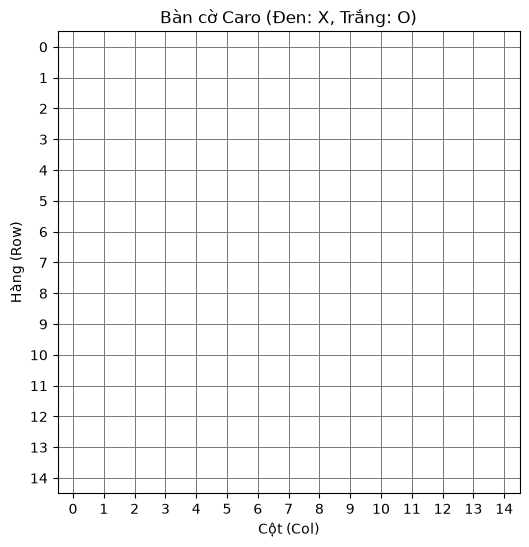

In [7]:
def draw_board(board: np.ndarray, last_move=None, ax=None):
    """Vẽ bàn cờ Caro với quân Đen (X) và quân Trắng (O)."""
    size = board.shape[0]
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))

    ax.set_xlim(-0.5, size - 0.5)
    ax.set_ylim(size - 0.5, -0.5)
    ax.set_xticks(range(size))
    ax.set_yticks(range(size))
    ax.grid(True, color="#777777", linewidth=0.7)
    ax.set_aspect("equal")

    # Vẽ quân cờ
    for x, y in zip(*np.where(board != 0)):
        color = "black" if board[x, y] == 1 else "white"
        symbol = "X" if board[x, y] == 1 else "O"
        text_color = "white" if board[x, y] == 1 else "black"

        ax.scatter(y, x, s=200, c=color, edgecolors="black", linewidths=1.5, zorder=3)
        ax.text(y, x, symbol, ha="center", va="center", color=text_color,
                fontsize=9, fontweight="bold", zorder=4)

    # Đánh dấu nước đi mới nhất
    if last_move is not None:
        lx, ly = last_move
        ax.scatter(ly, lx, s=320, facecolors="none", edgecolors="red", linewidths=2.5, zorder=5)

    ax.set_xlabel("Cột (Col)")
    ax.set_ylabel("Hàng (Row)")
    ax.set_title("Bàn cờ Caro (Đen: X, Trắng: O)")
    return ax


# Vẽ thử bàn cờ rỗng
test_env = GomokuEnv(config)
draw_board(test_env.board)
plt.show()


## 4. Kiến trúc Mạng Nơ-ron (SE-ResNet Thuần Tích Chập)

- **Đầu vào 4 kênh:** Nhận diện cả quân cờ, điểm nóng gần nhất và lượt đi.
- **Khối SE-ResBlock:** 2 lớp `Conv 3x3` + `BatchNorm` + **SE Attention** (tự động hiệu chỉnh trọng số các kênh đặc trưng quan trọng).
- **Policy Head thuần tích chập (Fully-Convolutional):** `Conv 1x1 -> BN -> ReLU -> Conv 1x1 -> Flatten`. Bảo toàn tính đối xứng không gian 2D, thích ứng linh hoạt với bất kỳ kích thước bàn cờ nào.
- **Value Head:** `Conv 1x1 + AdaptiveAvgPool2d(1) + MLP -> Tanh` xuất giá trị vô hướng $[-1, 1]$.


In [8]:
class SEBlock(nn.Module):
    """Khối chú ý kênh Squeeze-and-Excitation."""

    def __init__(self, channels: int, reduction: int = 8):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.layers = nn.Sequential(
            nn.Linear(channels, hidden, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch, channels, _, _ = x.shape
        scale = self.layers(self.pool(x).view(batch, channels))
        return x * scale.view(batch, channels, 1, 1)


class SEResBlock(nn.Module):
    """Khối Residual tích hợp SE Channel Attention."""

    def __init__(self, channels: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)
        self.se = SEBlock(channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.se(self.bn2(self.conv2(out)))
        return F.relu(out + residual, inplace=True)


class GomokuNetAlphaZero(nn.Module):
    """Mạng Fully-Convolutional SE-ResNet Dual-Head chuẩn AlphaZero cho cờ Caro."""

    def __init__(self, config: Config):
        super().__init__()
        channels = config.channels

        # Lớp stem nhận tensor 4 kênh trạng thái
        self.stem = nn.Sequential(
            nn.Conv2d(4, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

        # Thân mạng gồm các khối SE-ResBlock
        self.backbone = nn.Sequential(*[
            SEResBlock(channels) for _ in range(config.residual_blocks)
        ])

        # Policy Head thuần tích chập (Fully-Convolutional)
        self.policy = nn.Sequential(
            nn.Conv2d(channels, 32, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1),
            nn.Flatten()  # (B, 1, H, W) -> (B, H * W)
        )

        # Value Head: Tích chập + Adaptive Pooling + MLP
        self.value_conv = nn.Sequential(
            nn.Conv2d(channels, 32, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.value_fc = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Tanh()
        )

    def forward(self, state: torch.Tensor):
        features = self.backbone(self.stem(state))
        policy_logits = self.policy(features)

        v = self.value_conv(features)
        v = F.adaptive_avg_pool2d(v, (1, 1)).flatten(1)
        value = self.value_fc(v).squeeze(-1)

        return policy_logits, value


## 5. Tăng cường dữ liệu đối xứng D4 (Symmetry Augmentation)

Bàn cờ vuông có 8 phép biến đổi đối xứng tương đương (nhóm dihedral $D_4$): 4 phép quay ($0^\circ, 90^\circ, 180^\circ, 270^\circ$) và 4 phép lật đối xứng.
Toàn bộ 4 kênh trạng thái và vector policy được xoay lật đồng bộ, nhân 8 lần dữ liệu huấn luyện miễn phí.


In [9]:
def augment_d4(state: np.ndarray, policy: np.ndarray, board_size: int):
    """Sinh 8 biến thể đối xứng D4 cho cặp (state, policy).
    state: (4, H, W) -> phép xoay và lật thực hiện trên 2 trục không gian (-2, -1).
    policy: (H * W,) -> reshape thành (H, W), xoay/lật, rồi flatten lại.
    """
    policy_grid = policy.reshape(board_size, board_size)
    for k in range(4):
        # 4 phép quay 90 độ
        rotated_state = np.rot90(state, k, axes=(-2, -1)).copy()
        rotated_policy = np.rot90(policy_grid, k).copy()
        yield rotated_state, rotated_policy.ravel()

        # 4 phép lật ngang kết hợp quay
        flipped_state = np.flip(rotated_state, axis=-1).copy()
        flipped_policy = np.flip(rotated_policy, axis=-1).copy()
        yield flipped_state, flipped_policy.ravel()


## 6. Thuật toán MCTS Vectorized & Soft Tactical Prior

- **Vectorized PUCT:** Tối ưu hóa bước duyệt chọn node con bằng mảng NumPy thay vì duyệt lặp từng dictionary trong Python (nhanh hơn gấp nhiều lần).
- **Soft Tactical Prior:** Điểm thưởng chiến thuật (thắng ngay, chặn 5, tạo 4 mở, chặn 3 mở) được cộng thẳng vào logits của mạng trước khi Softmax, giúp MCTS tập trung tìm kiếm các nước cờ sinh tử và dạy lại mạng nơ-ron qua Cross-Entropy Loss.
- **Inference Mode:** Sử dụng `torch.inference_mode()` để loại bỏ hoàn toàn chi phí tạo autograd graph khi mô phỏng.


In [10]:
class Node:
    """Nút trên cây tìm kiếm MCTS."""

    def __init__(self, prior: float = 0.0):
        self.prior = float(prior)
        self.children = {}
        self.visit_count = 0
        self.value_sum = 0.0

    @property
    def q(self) -> float:
        return self.value_sum / self.visit_count if self.visit_count > 0 else 0.0


class MCTS:
    """Bộ tìm kiếm Monte Carlo Tree Search theo chuẩn AlphaZero kết hợp Soft Prior & NumPy Vectorization."""

    def __init__(self, model: nn.Module, config: Config, device: torch.device):
        self.model = model
        self.config = config
        self.device = device

    @torch.inference_mode()
    def evaluate(self, state: np.ndarray, legal_mask: np.ndarray, tactical_bonuses: np.ndarray = None):
        """Dùng mạng nơ-ron đánh giá prior xác suất và value của trạng thái kết hợp Soft Prior."""
        tensor = torch.from_numpy(state).unsqueeze(0).to(self.device)
        logits, value = self.model(tensor)
        logits = logits[0].float().cpu().numpy()

        # Cộng điểm thưởng chiến thuật (Soft Prior) vào logits trước khi softmax
        if tactical_bonuses is not None:
            logits += tactical_bonuses

        # Che các nước đi không hợp lệ
        logits[~legal_mask] = -1e9
        probs = np.exp(logits - logits.max())
        probs_sum = probs.sum()
        if probs_sum > 0:
            probs /= probs_sum
        else:
            probs[legal_mask] = 1.0 / legal_mask.sum()
        return probs, float(value.item())

    def run(self, env: GomokuEnv, add_noise: bool = True, temperature: float = 1.0) -> np.ndarray:
        """Thực hiện chu kỳ mô phỏng MCTS và trả về vector xác suất nước đi."""
        root = Node()
        legal = env.board.ravel() == 0

        # Soft Tactical Prior: Tính tại nút gốc để định hướng cây tìm kiếm ngay từ đầu
        bonuses = env.get_tactical_bonuses(env.current_player)
        priors, _ = self.evaluate(env.state(), legal, tactical_bonuses=bonuses)
        actions = np.flatnonzero(legal)

        # Thêm nhiễu Dirichlet tại nút gốc khi tự đấu (đã tinh chỉnh theo bàn cờ)
        if add_noise and len(actions) > 0:
            noise = np.random.dirichlet([self.config.dirichlet_alpha] * len(actions))
            priors[actions] = (
                (1.0 - self.config.dirichlet_epsilon) * priors[actions]
                + self.config.dirichlet_epsilon * noise
            )

        for action in actions:
            root.children[int(action)] = Node(priors[action])

        # Vòng lặp mô phỏng
        for _ in range(self.config.simulations):
            board = env.board.copy()
            player = env.current_player
            last_mv = env.last_move
            node = root
            path = [node]

            # 1. Selection (Tối ưu hóa tốc độ bằng NumPy vectorization)
            while node.children:
                child_items = list(node.children.items())
                act_list = np.array([item[0] for item in child_items], dtype=np.int64)
                priors_arr = np.array([item[1].prior for item in child_items], dtype=np.float32)
                visits_arr = np.array([item[1].visit_count for item in child_items], dtype=np.float32)
                q_arr = np.array([item[1].q for item in child_items], dtype=np.float32)

                scale = math.sqrt(node.visit_count + 1)
                u = self.config.c_puct * priors_arr * scale / (1.0 + visits_arr)
                puct_scores = -q_arr + u
                best_idx = np.argmax(puct_scores)

                action = int(act_list[best_idx])
                node = child_items[best_idx][1]

                x, y = divmod(action, env.size)
                board[x, y] = player
                last_mv = (x, y)
                path.append(node)

                if env.check_win(x, y, board=board):
                    value = 1.0
                    break
                player = -player
            else:
                # 2. Expansion & Evaluation (dùng trạng thái 4 kênh, đánh giá mạng nơ-ron trực tiếp)
                cur_state = np.zeros((4, env.size, env.size), dtype=np.float32)
                cur_state[0] = (board == player).astype(np.float32)
                cur_state[1] = (board == -player).astype(np.float32)
                if last_mv is not None:
                    cur_state[2, last_mv[0], last_mv[1]] = 1.0
                if player == 1:
                    cur_state[3].fill(1.0)

                cur_legal = board.ravel() == 0
                if not cur_legal.any():
                    value = 0.0  # Bàn cờ đầy: hòa
                else:
                    # Đánh giá trực tiếp qua mạng nơ-ron để tăng tốc và giữ độ sâu MCTS tự nhiên
                    priors, value = self.evaluate(cur_state, cur_legal)
                    for act in np.flatnonzero(cur_legal):
                        node.children[int(act)] = Node(priors[act])

            # 3. Backup (đổi dấu value khi truyền ngược)
            for visited in reversed(path):
                visited.visit_count += 1
                visited.value_sum += value
                value = -value

        # Tính phân phối xác suất từ số lượt thăm visit_count
        actions = np.array(list(root.children.keys()), dtype=np.int64)
        counts = np.array([root.children[a].visit_count for a in actions], dtype=np.float64)

        if temperature <= 1e-6 or counts.sum() == 0:
            probs = np.zeros_like(counts)
            probs[np.argmax(counts)] = 1.0
        else:
            counts = counts ** (1.0 / temperature)
            probs = counts / counts.sum()

        policy = np.zeros(env.size * env.size, dtype=np.float32)
        policy[actions] = probs
        return policy


## 7. Replay Buffer & Bể đối thủ lịch sử (Opponent Pool)

- **Replay Buffer:** Lưu trữ bộ ba `(trạng thái 4 kênh, phân phối MCTS, kết quả ván đấu)` và tự động tăng cường đối xứng D4.
- **Opponent Pool:** Lưu lại các snapshot mô hình từ các vòng trước. Khi tự đấu, 20% số ván được chọn để thi đấu với mô hình lịch sử, giúp bot không bị phụ thuộc lối đánh cục bộ (chống Policy Cycling).


In [11]:
class ReplayBuffer:
    """Bộ đệm kinh nghiệm tái tạo ván đấu với D4 Augmentation."""

    def __init__(self, capacity: int):
        self.data = deque(maxlen=capacity)

    def add_game(self, records, winner: int):
        """Thêm các bước cờ từ ván đấu hoàn chỉnh vào buffer."""
        for state, policy, player in records:
            if winner == 0:
                target = 0.0
            elif winner == player:
                target = 1.0
            else:
                target = -1.0

            # Áp dụng 8 phép biến đổi đối xứng D4 trên tensor 4 kênh
            for aug_state, aug_policy in augment_d4(state, policy, state.shape[-1]):
                self.data.append((aug_state, aug_policy, target))

    def sample(self, batch_size: int):
        """Lấy ngẫu nhiên một mini-batch từ bộ đệm."""
        batch = random.sample(self.data, batch_size)
        states, policies, values = zip(*batch)
        return (
            torch.tensor(np.array(states), dtype=torch.float32),
            torch.tensor(np.array(policies), dtype=torch.float32),
            torch.tensor(values, dtype=torch.float32)
        )

    def __len__(self) -> int:
        return len(self.data)


class OpponentPool:
    """Bể đối thủ lịch sử (Opponent Pool) lưu trữ các phiên bản checkpoint cũ."""

    def __init__(self, max_size: int = 8):
        self.max_size = max_size
        self.pool = []

    def add(self, model: nn.Module):
        """Lưu một bản sao trọng số mô hình lên CPU."""
        state_dict = {k: v.clone().cpu() for k, v in model.state_dict().items()}
        if len(self.pool) >= self.max_size:
            self.pool.pop(0)  # FIFO
        self.pool.append(state_dict)

    def sample_opponent(self, config: Config, device: torch.device):
        """Lấy ngẫu nhiên một mô hình lịch sử làm đối thủ thi đấu."""
        if not self.pool:
            return None
        state_dict = random.choice(self.pool)
        opponent = GomokuNetAlphaZero(config).to(device)
        opponent.load_state_dict(state_dict)
        opponent.eval()
        return opponent

    def __len__(self) -> int:
        return len(self.pool)


## 8. Quy trình Huấn luyện Tự đấu (Self-Play, Opponent Pool & Resume)

- Tự đấu tích hợp **Opponent Pool**: 80% ván tự đấu với chính mình, 20% ván đấu lại các đối thủ lịch sử.
- Hỗ trợ khôi phục tiến trình tự động (`caro_v2_model_latest.pth`, `caro_v2_model_best.pth`).
- Mất mát kết hợp: Policy Cross-Entropy + Value MSE, tăng tốc qua `torch.amp.autocast` (FP16).


In [15]:
def self_play_game(model: nn.Module, config: Config, device: torch.device, opponent_model: nn.Module = None):
    """Tự đấu một ván hoàn chỉnh bằng MCTS để thu thập dữ liệu.
    Nếu có opponent_model: model chính đấu với opponent_model (ngẫu nhiên đổi lượt đi).
    """
    env = GomokuEnv(config)
    search_main = MCTS(model, config, device)
    search_opp = MCTS(opponent_model, config, device) if opponent_model is not None else search_main

    # 0 = self-play thuần túy; 1: model chính đi trước (Đen); -1: model chính đi sau (Trắng)
    main_player = random.choice([1, -1]) if opponent_model is not None else 0
    records = []

    while not env.done:
        state = env.state()
        cur_search = search_main if (main_player == 0 or env.current_player == main_player) else search_opp

        # Nước cờ khẩn cấp (thắng ngay, chặn 5, tạo 4 mở, chặn 4 mở) -> đi ngay để đảm bảo chất lượng ván đấu
        forced = env.tactical_action(env.current_player)
        if forced is not None:
            policy = np.zeros(config.board_size ** 2, dtype=np.float32)
            policy[forced] = 1.0
        else:
            # Nhiệt độ cao ở các nước đầu để đa dạng hóa khai cuộc
            temperature = 1.0 if len(records) < config.temperature_moves else 0.1
            policy = cur_search.run(env, add_noise=True, temperature=temperature)

        # Chỉ lưu kinh nghiệm từ góc nhìn của model chính (hoặc cả 2 nếu self-play thuần)
        if main_player == 0 or env.current_player == main_player:
            records.append((state, policy, env.current_player))

        action = int(np.random.choice(len(policy), p=policy))
        env.step(action)

    return records, env.winner


def train_model(model: nn.Module, buffer: ReplayBuffer, config: Config,
                device: torch.device, optimizer: torch.optim.Optimizer,
                scaler: torch.amp.GradScaler):
    """Cập nhật trọng số mạng nơ-ron qua các mini-batch từ ReplayBuffer."""
    model.train()
    metrics = {"total": [], "policy": [], "value": []}

    for _ in range(config.train_steps):
        if len(buffer) < config.batch_size:
            break

        states, target_policy, target_value = buffer.sample(config.batch_size)
        states = states.to(device)
        target_policy = target_policy.to(device)
        target_value = target_value.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            logits, values = model(states)
            # Cross-Entropy Policy Loss
            policy_loss = -(target_policy * F.log_softmax(logits, dim=1)).sum(1).mean()
            # MSE Value Loss
            value_loss = F.mse_loss(values, target_value)
            loss = policy_loss + value_loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        metrics["total"].append(loss.item())
        metrics["policy"].append(policy_loss.item())
        metrics["value"].append(value_loss.item())

    return metrics


# Khởi tạo mô hình V2, tối ưu hóa, bộ đệm và đối thủ lịch sử
model = GomokuNetAlphaZero(config).to(DEVICE)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay
)
scaler = torch.amp.GradScaler(device=DEVICE.type, enabled=USE_AMP)
replay_buffer = ReplayBuffer(config.buffer_capacity)
opponent_pool = OpponentPool(config.pool_size)

# Đường dẫn checkpoint V2 riêng biệt để không xung đột phiên bản cũ
latest_ckpt_path = os.path.join(SAVE_DIR, f"caro_v2_model_{config.board_size}x{config.board_size}_latest.pth")
best_ckpt_path = os.path.join(SAVE_DIR, f"caro_v2_model_{config.board_size}x{config.board_size}_best.pth")
history_log_path = os.path.join(SAVE_DIR, f"caro_v2_history_{config.board_size}x{config.board_size}.json")

history = {"total": [], "policy": [], "value": []}
start_iteration = 0
best_loss = float("inf")

# Phục hồi checkpoint V2 nếu có sẵn
if os.path.exists(latest_ckpt_path):
    try:
        ckpt = torch.load(latest_ckpt_path, map_location=DEVICE)
        model.load_state_dict(ckpt["model_state_dict"])
        if "optimizer_state_dict" in ckpt:
            optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        start_iteration = ckpt.get("iteration", 0)
        best_loss = ckpt.get("best_loss", float("inf"))
        print(f"Đã nạp lại checkpoint V2 từ: {latest_ckpt_path} (Tiếp tục từ vòng {start_iteration + 1})")
        if os.path.exists(history_log_path):
            with open(history_log_path, "r", encoding="utf-8") as hf:
                history = json.load(hf)
            print(f"Đã nạp lịch sử huấn luyện: {len(history['total'])} vòng trước đó.")
    except Exception as e:
        print(f"Không thể nạp checkpoint V2 cũ ({e}). Khởi tạo huấn luyện V2 từ đầu.")
else:
    print("Khởi tạo mô hình V2 mới từ đầu (chưa có checkpoint V2).")

# Đưa bản khởi tạo đầu tiên vào Opponent Pool
opponent_pool.add(model)

# Vòng lặp huấn luyện chính
total_iterations = config.num_iterations
print(f"\nBắt đầu huấn luyện V2: từ vòng {start_iteration + 1} đến {start_iteration + total_iterations}...\n")

import time

for it in tqdm(range(start_iteration, start_iteration + total_iterations), desc="Tiến trình tự đấu & Train"):
    model.eval()
    iter_start_time = time.time()

    for game_idx in range(config.self_play_games):
        t_game_start = time.time()
        # Quyết định đấu với chính mình hay đấu với đối thủ trong Opponent Pool
        use_pool = (len(opponent_pool) > 0) and (random.random() < config.pool_play_ratio)
        opp_net = opponent_pool.sample_opponent(config, DEVICE) if use_pool else None

        game_records, game_winner = self_play_game(model, config, DEVICE, opponent_model=opp_net)
        replay_buffer.add_game(game_records, game_winner)

        t_game_dur = time.time() - t_game_start
        w_str = "Hòa" if game_winner == 0 else ("Đen thắng" if game_winner == 1 else "Trắng thắng")
        opp_str = "vs Pool" if use_pool else "Self-Play"
        print(f"    -> [Ván {game_idx + 1}/{config.self_play_games} ({opp_str})] {len(game_records)} nước ({t_game_dur:.1f}s) - Kết quả: {w_str}")

    metrics = train_model(model, replay_buffer, config, DEVICE, optimizer, scaler)
    for key in history:
        if metrics[key]:
            history[key].append(float(np.mean(metrics[key])))

    cur_total_loss = history["total"][-1] if history["total"] else 0.0
    cur_policy_loss = history["policy"][-1] if history["policy"] else 0.0
    cur_value_loss = history["value"][-1] if history["value"] else 0.0
    iter_dur = time.time() - iter_start_time

    print(f"  Vòng {it + 1} hoàn thành trong {iter_dur:.1f}s: "
          f"Tổng loss = {cur_total_loss:.4f}, "
          f"Policy loss = {cur_policy_loss:.4f}, "
          f"Value loss = {cur_value_loss:.4f} "
          f"(Bộ đệm: {len(replay_buffer)} mẫu | Pool: {len(opponent_pool)} models)")

    # Lưu checkpoint định kỳ hoặc bản tốt nhất
    ckpt_data = {
        "iteration": it + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_loss": best_loss,
        "config": config.__dict__
    }
    torch.save(ckpt_data, latest_ckpt_path)

    if cur_total_loss > 0 and cur_total_loss < best_loss:
        best_loss = cur_total_loss
        ckpt_data["best_loss"] = best_loss
        torch.save(ckpt_data, best_ckpt_path)
        print(f"  -> Đã cập nhật best checkpoint mới: Loss = {best_loss:.4f}")

    if (it + 1) % config.save_interval == 0:
        periodic_path = os.path.join(SAVE_DIR, f"caro_v2_model_{config.board_size}x{config.board_size}_iter_{it + 1}.pth")
        torch.save(ckpt_data, periodic_path)
        opponent_pool.add(model)  # Cập nhật model vào Opponent Pool

    with open(history_log_path, "w", encoding="utf-8") as hf:
        json.dump(history, hf, indent=2)

print(f"\nHuấn luyện V2 hoàn thành! Toàn bộ checkpoint đã lưu an toàn tại: {SAVE_DIR}")


Đã nạp lại checkpoint V2 từ: .\checkpoints\caro_v2_model_15x15_latest.pth (Tiếp tục từ vòng 64)
Đã nạp lịch sử huấn luyện: 63 vòng trước đó.

Bắt đầu huấn luyện V2: từ vòng 64 đến 113...



Tiến trình tự đấu & Train:   0%|          | 0/50 [00:00<?, ?it/s]

    -> [Ván 1/5 (Self-Play)] 225 nước (106.7s) - Kết quả: Hòa
    -> [Ván 2/5 (Self-Play)] 225 nước (121.2s) - Kết quả: Hòa
    -> [Ván 3/5 (Self-Play)] 225 nước (114.9s) - Kết quả: Hòa
    -> [Ván 4/5 (Self-Play)] 225 nước (127.0s) - Kết quả: Hòa
    -> [Ván 5/5 (Self-Play)] 225 nước (117.4s) - Kết quả: Hòa


Tiến trình tự đấu & Train:   2%|▏         | 1/50 [09:47<8:00:03, 587.84s/it]

  Vòng 64 hoàn thành trong 587.8s: Tổng loss = 0.4675, Policy loss = 0.4675, Value loss = 0.0000 (Bộ đệm: 9000 mẫu | Pool: 1 models)
  -> Đã cập nhật best checkpoint mới: Loss = 0.4675
    -> [Ván 1/5 (Self-Play)] 225 nước (130.0s) - Kết quả: Hòa
    -> [Ván 2/5 (Self-Play)] 225 nước (111.2s) - Kết quả: Hòa
    -> [Ván 3/5 (Self-Play)] 225 nước (104.4s) - Kết quả: Hòa
    -> [Ván 4/5 (vs Pool)] 112 nước (91.6s) - Kết quả: Hòa
    -> [Ván 5/5 (Self-Play)] 225 nước (74.9s) - Kết quả: Hòa


Tiến trình tự đấu & Train:   4%|▍         | 2/50 [18:20<7:14:55, 543.65s/it]

... (17 outputs left out)

Tiến trình tự đấu & Train:  22%|██▏       | 11/50 [1:36:24<5:37:31, 519.27s/it]

  Vòng 74 hoàn thành trong 469.4s: Tổng loss = 0.4420, Policy loss = 0.4420, Value loss = 0.0000 (Bộ đệm: 30000 mẫu | Pool: 3 models)
  -> Đã cập nhật best checkpoint mới: Loss = 0.4420
    -> [Ván 1/5 (Self-Play)] 225 nước (70.7s) - Kết quả: Hòa
    -> [Ván 2/5 (Self-Play)] 225 nước (80.4s) - Kết quả: Hòa


Tiến trình tự đấu & Train:  22%|██▏       | 11/50 [1:40:10<5:55:08, 546.38s/it]


KeyboardInterrupt: 

## 9. Biểu đồ đánh giá huấn luyện (Training Curves Visualization)

Trực quan hóa tiến trình giảm mất mát (Loss) qua từng vòng lặp: Total Loss, Policy Loss, và Value Loss.
Đường nét đứt màu đỏ biểu thị đường trung bình trượt (Moving Average) làm mượt biến động giữa các ván.


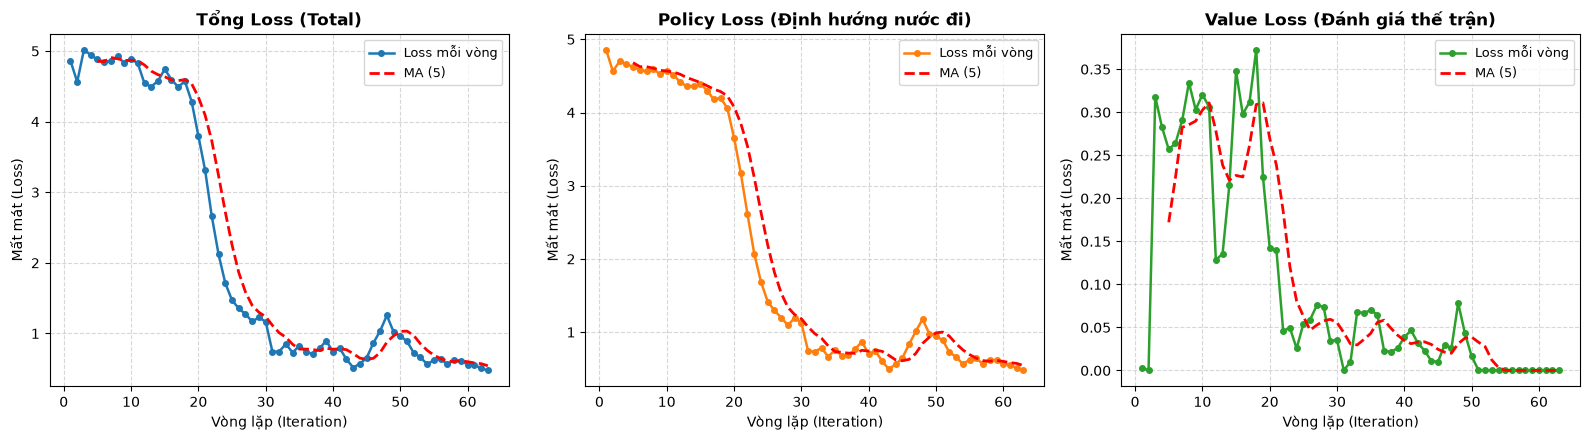

Biểu đồ đã được lưu tại: .\checkpoints\caro_v2_training_curves_15x15.png


In [13]:
if history["total"]:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    titles = ("Tổng Loss (Total)", "Policy Loss (Định hướng nước đi)", "Value Loss (Đánh giá thế trận)")
    colors = ("#1f77b4", "#ff7f0e", "#2ca02c")
    x_vals = range(1, len(history["total"]) + 1)

    for ax, key, title, color in zip(axes, ("total", "policy", "value"), titles, colors):
        y_vals = history[key]
        ax.plot(x_vals, y_vals, marker="o", markersize=4, color=color, linewidth=1.8, label="Loss mỗi vòng")

        if len(y_vals) >= 5:
            window = min(5, len(y_vals))
            ma = np.convolve(y_vals, np.ones(window)/window, mode="valid")
            ax.plot(range(window, len(y_vals) + 1), ma, color="red", linestyle="--", linewidth=2, label=f"MA ({window})")

        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.set_xlabel("Vòng lặp (Iteration)")
        ax.set_ylabel("Mất mát (Loss)")
        ax.legend(fontsize=9)
        ax.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    curve_img_path = os.path.join(SAVE_DIR, f"caro_v2_training_curves_{config.board_size}x{config.board_size}.png")
    plt.savefig(curve_img_path, dpi=150)
    plt.show()
    print(f"Biểu đồ đã được lưu tại: {curve_img_path}")
else:
    print("Chưa có dữ liệu huấn luyện để vẽ biểu đồ.")


## 10. Xuất mô hình sang ONNX & TorchScript

Xuất trọng số của mạng SE-ResNet V2 sang định dạng **ONNX (Opset 18)** và **TorchScript** (`.pt`):
- Tensor đầu vào 4 kênh: `(batch_size, 4, H, W)`.
- File `.onnx` có thể triển khai chạy trực tiếp trên trình duyệt Web (qua ONNX Runtime WebAssembly trong `webdemo/`) hoặc app mobile.


In [14]:
# Xuất mô hình sang định dạng ONNX và TorchScript
model.eval()
onnx_export_path = os.path.join(SAVE_DIR, f"caro_v2_model_{config.board_size}x{config.board_size}.onnx")
ts_export_path = os.path.join(SAVE_DIR, f"caro_v2_model_{config.board_size}x{config.board_size}.pt")

# Tensor giả lập đầu vào 4 kênh (batch_size=1, channels=4, H, W)
dummy_input = torch.randn(1, 4, config.board_size, config.board_size, device=DEVICE)

try:
    # 1. Xuất ONNX với chuẩn Opset 18 hiện đại
    torch.onnx.export(
        model,
        dummy_input,
        onnx_export_path,
        input_names=["board_state"],
        output_names=["policy_logits", "value"],
        dynamic_axes={
            "board_state": {0: "batch"},
            "policy_logits": {0: "batch"},
            "value": {0: "batch"}
        },
        opset_version=18
    )
    print(f"Đã xuất ONNX thành công: {onnx_export_path}")
    print(f"Kích thước file ONNX: {os.path.getsize(onnx_export_path) / (1024**2):.2f} MB")
except Exception as e:
    print(f"Lỗi khi xuất ONNX: {e}")
    print("Mẹo: Cần cài đặt onnx nếu chưa có: pip install onnx onnxscript")

try:
    # 2. Xuất TorchScript
    traced_model = torch.jit.trace(model, dummy_input)
    traced_model.save(ts_export_path)
    print(f"Đã xuất TorchScript thành công: {ts_export_path}")
except Exception as e:
    print(f"Lỗi khi xuất TorchScript: {e}")


<ipython-input>:11: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `GomokuNetAlphaZero([...]` with `torch.export.export(..., strict=False)`...


W1104 13:25:13.043000 25104 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


[torch.onnx] Obtain model graph for `GomokuNetAlphaZero([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Đã xuất ONNX thành công: .\checkpoints\caro_v2_model_15x15.onnx
Kích thước file ONNX: 0.11 MB


.\.venv\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
.\.venv\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Đã xuất TorchScript thành công: .\checkpoints\caro_v2_model_15x15.pt


## 11. Demo thực nghiệm (Đấu trực tiếp với bot)

Đặt `PLAY_INTERACTIVE = True` để bắt đầu ván đấu đối kháng trực tiếp trong Notebook. Nhập tọa độ dạng `hàng,cột` (ví dụ: `7,7`).
Mặc định `PLAY_INTERACTIVE = False` để lệnh **Run All** chạy qua mượt mà không bị treo đợi người dùng nhập phím.


In [ ]:
PLAY_INTERACTIVE = False  # Đổi thành True để chơi trực tiếp với bot

if PLAY_INTERACTIVE:
    # Tự động nạp bản V2 có loss tốt nhất (nếu có)
    if os.path.exists(best_ckpt_path):
        ckpt = torch.load(best_ckpt_path, map_location=DEVICE)
        model.load_state_dict(ckpt["model_state_dict"])
        print(f"Đã tải trọng số tốt nhất V2 từ: {best_ckpt_path}")
    else:
        print("Dùng mô hình hiện tại trong bộ nhớ.")

    env = GomokuEnv(config)
    search = MCTS(model.eval(), config, DEVICE)

    print("\n=== BẮT ĐẦU VÁN ĐẤU CARO VỚI AI V2 ===")
    print(f"Bạn cầm quân Đen (X) đi trước. Nhập tọa độ 'hàng,cột' từ 0 đến {env.size - 1}")
    draw_board(env.board)
    plt.show()

    while not env.done:
        if env.current_player == 1:
            move_str = input(f"Lượt Đen (Bạn); nhập hàng,cột (0-{env.size - 1}): ")
            try:
                row, col = (int(p.strip()) for p in move_str.split(","))
                action = row * env.size + col
                env.step(action)
            except (ValueError, RuntimeError) as error:
                print(f"Nước đi không hợp lệ: {error}")
                continue
        else:
            state = env.state()
            legal = env.board.ravel() == 0

            # Ưu tiên nước chiến thuật khẩn cấp: Thắng ngay (15), Chặn thắng (12), Tạo 4 mở (10), Chặn 4 mở (8)
            forced = env.tactical_action(-1)

            if forced is None:
                policy = search.run(env, add_noise=False, temperature=0.0)
                policy[~legal] = 0
                action = int(np.argmax(policy))
            else:
                action = forced

            env.step(action)
            rx, ry = divmod(action, env.size)
            print(f"Bot (Trắng O) vừa đánh vào ô: hàng {rx}, cột {ry}")

        draw_board(env.board, env.last_move)
        plt.show()

    # Kết quả chung cuộc
    if env.winner == 0:
        print("Kết quả: Hòa cờ!")
    elif env.winner == 1:
        print("Chúc mừng! Bạn đã giành chiến thắng!")
    else:
        print("Bot AI đã chiến thắng!")
else:
    print("Chế độ chơi tương tác đang tắt (PLAY_INTERACTIVE = False).")
    print("Để chơi trực tiếp với bot, hãy gán PLAY_INTERACTIVE = True và chạy lại cell này.")
